# 1. Import Libraries


In [32]:
# Import required libraries
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style for clear visuals
sns.set_theme(style="whitegrid")


# 2. Project Paths


In [33]:
from pathlib import Path

# Get the current working directory
CURRENT_DIR = Path.cwd()

# If notebook is running from the notebooks folder,
# move one level up to the project root.
if CURRENT_DIR.name == "notebooks":
    BASE_DIR = CURRENT_DIR.parent
else:
    BASE_DIR = CURRENT_DIR

DATA_DIR = BASE_DIR / "data" / "raw"

EMAIL_DATA_PATH = DATA_DIR / "enron_spam_data.csv"
URL_DATA_PATH = DATA_DIR / "PhiUSIIL_Phishing_URL_Dataset.csv"

OUTPUT_DIR = BASE_DIR / "outputs" / "eda"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project Root:", BASE_DIR)
print("Email Dataset:", EMAIL_DATA_PATH)
print("URL Dataset:", URL_DATA_PATH)
print("EDA Output:", OUTPUT_DIR)

Project Root: c:\Users\admin\Desktop\ML CP
Email Dataset: c:\Users\admin\Desktop\ML CP\data\raw\enron_spam_data.csv
URL Dataset: c:\Users\admin\Desktop\ML CP\data\raw\PhiUSIIL_Phishing_URL_Dataset.csv
EDA Output: c:\Users\admin\Desktop\ML CP\outputs\eda


# 3. Email Spam/Ham Dataset


## 3.1 Load Dataset


In [34]:
print(f"Loading email dataset from: {EMAIL_DATA_PATH}")
try:
    df_email = pd.read_csv(EMAIL_DATA_PATH)
    print("Dataset loaded successfully!")
except FileNotFoundError:
    print("ERROR: Email dataset not found. Please check the path.")
except Exception as e:
    print(f"ERROR: {e}")


Loading email dataset from: c:\Users\admin\Desktop\ML CP\data\raw\enron_spam_data.csv
Dataset loaded successfully!


## 4.2 Dataset Shape


In [35]:
rows, columns = df_email.shape
print(f"Number of rows (emails): {rows}")
print(f"Number of columns (features): {columns}")


Number of rows (emails): 33716
Number of columns (features): 5


## 4.3 Column Names


In [36]:
print("Email Dataset Column Names:")
print(df_email.columns.tolist())


Email Dataset Column Names:
['Unnamed: 0', 'Subject', 'Message', 'Spam/Ham', 'Date']


## 4.4 Data Types


In [37]:
print("Email Dataset Data Types:")
df_email.info()


Email Dataset Data Types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33716 entries, 0 to 33715
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  33716 non-null  int64 
 1   Subject     33716 non-null  object
 2   Message     33664 non-null  object
 3   Spam/Ham    33716 non-null  object
 4   Date        33716 non-null  object
dtypes: int64(1), object(4)
memory usage: 1.3+ MB


## 4.5 First 5 Records


In [38]:
# Display the first 5 rows of the dataset
df_email.head()


,Unnamed: 0,Subject,Message,Spam/Ham,Date
0,0,christmas tree farm pictures,NaN,ham,1999-12-10
1,1,"vastar resources , inc .","gary , production from the high island larger ...",ham,1999-12-13
2,2,calpine daily gas nomination,- calpine daily gas nomination 1 . doc,ham,1999-12-14
3,3,re : issue,fyi - see note below - already done .\nstella\...,ham,1999-12-14
4,4,meter 7268 nov allocation,fyi .\n- - - - - - - - - - - - - - - - - - - -...,ham,1999-12-14


## 4.6 Missing Values


In [39]:
missing_values = df_email.isnull().sum().sort_values(ascending=False)
print("Missing values per column:")
print(missing_values)
print(f"\nTotal missing values in dataset: {missing_values.sum()}")


Missing values per column:
Message       52
Unnamed: 0     0
Subject        0
Spam/Ham       0
Date           0
dtype: int64

Total missing values in dataset: 52


## 4.7 Duplicate Records


In [40]:
duplicate_rows = df_email.duplicated().sum()
print(f"Completely duplicate rows: {duplicate_rows}")
print(f"Duplicate percentage: {(duplicate_rows / len(df_email)) * 100:.2f}%")


Completely duplicate rows: 0
Duplicate percentage: 0.00%


## 4.8 Identify Target Column


In [41]:
# Identify the column containing our Spam/Ham labels
possible_target_columns = ["Spam/Ham", "spam", "label", "Label", "class", "Class"]
target_col = None

for column in possible_target_columns:
    if column in df_email.columns:
        target_col = column
        break

if target_col is None:
    print("WARNING: Could not automatically identify the target column.")
else:
    print(f"Target column identified as: '{target_col}'")


Target column identified as: 'Spam/Ham'


## 4.9 Spam vs Ham Class Distribution


In [42]:
class_distribution = df_email[target_col].value_counts(dropna=False)
print("Class Counts:")
print(class_distribution)

class_percentage = df_email[target_col].value_counts(normalize=True, dropna=False) * 100
print("\nClass Percentage:")
print(class_percentage.round(2))


Class Counts:
Spam/Ham
spam    17171
ham     16545
Name: count, dtype: int64

Class Percentage:
Spam/Ham
spam    50.93
ham     49.07
Name: proportion, dtype: float64


## 4.10 Class Distribution Visualization


Saved plot to: c:\Users\admin\Desktop\ML CP\outputs\eda\email_class_distribution.png


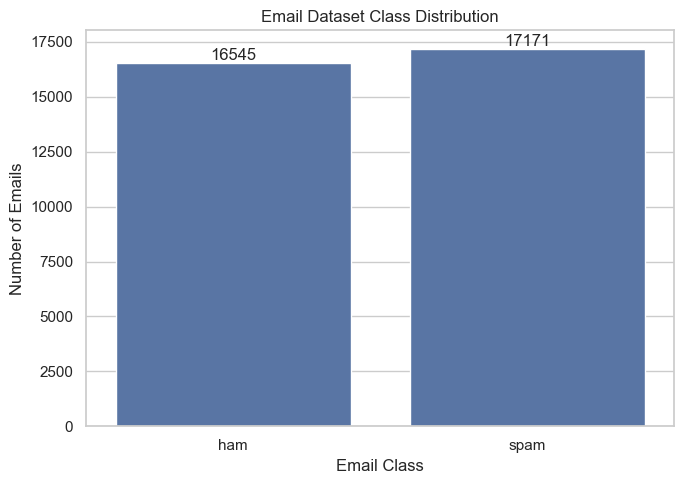

In [43]:
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df_email, x=target_col)
plt.title("Email Dataset Class Distribution")
plt.xlabel("Email Class")
plt.ylabel("Number of Emails")

# Add count labels on bars
for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()

# Save plot
plot_path = os.path.join(OUTPUT_DIR, "email_class_distribution.png")
plt.savefig(plot_path, dpi=300)
print(f"Saved plot to: {plot_path}")
plt.show()


## 4.11 Email Message Length Statistics


In [44]:
# Identify message column
possible_message_columns = ["Message", "message", "Body", "body", "text", "Text"]
message_col = None

for column in possible_message_columns:
    if column in df_email.columns:
        message_col = column
        break

if message_col:
    print(f"Message column identified as: {message_col}")
    
    # Calculate length (filling missing with empty string to avoid errors)
    message_length = df_email[message_col].fillna("").astype(str).str.len()
    
    print("\nMessage Length Statistics (in characters):")
    print(message_length.describe())
else:
    print("No message/body column found.")


Message column identified as: Message

Message Length Statistics (in characters):
count     33716.000000
mean       1628.556442
std        4207.797296
min           0.000000
25%         632.000000
50%         868.000000
75%        1674.000000
max      228353.000000
Name: Message, dtype: float64


## 4.12 Email Length Visualization


Saved plot to: c:\Users\admin\Desktop\ML CP\outputs\eda\email_message_length_distribution.png


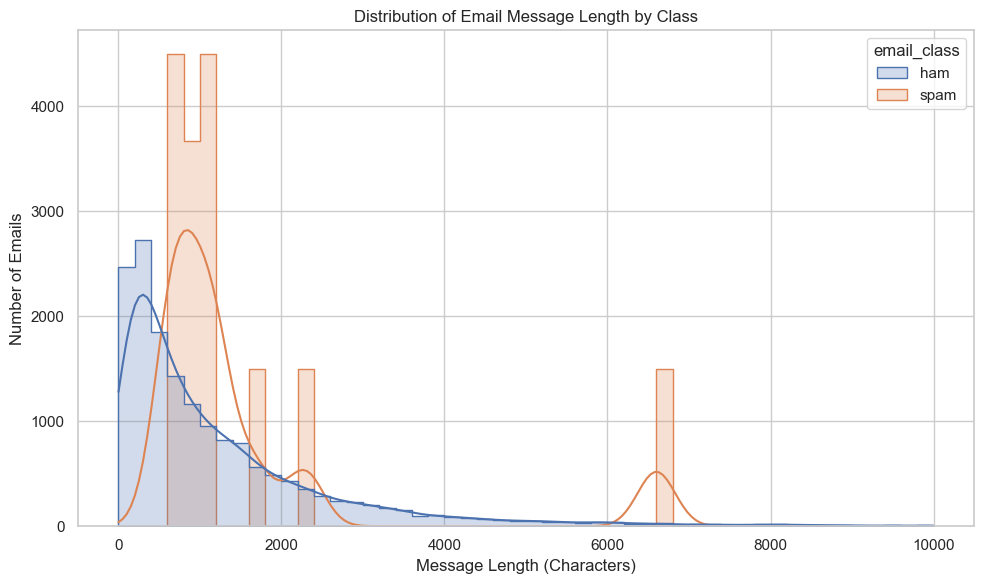


Average Email Length by Class:
             count         mean  median     max
email_class                                    
ham          16545  1676.289211   766.0  228353
spam         17171  1582.563858  1180.0    6600


In [45]:
if message_col:
    plot_df = pd.DataFrame({
        "message_length": message_length,
        "email_class": df_email[target_col]
    })
    
    # Filter out extremely long emails for a cleaner histogram
    plot_df_filtered = plot_df[plot_df["message_length"] < 10000]
    
    plt.figure(figsize=(10, 6))
    sns.histplot(data=plot_df_filtered, x="message_length", hue="email_class", bins=50, kde=True, element="step")
    plt.title("Distribution of Email Message Length by Class")
    plt.xlabel("Message Length (Characters)")
    plt.ylabel("Number of Emails")
    plt.tight_layout()
    
    plot_path = os.path.join(OUTPUT_DIR, "email_message_length_distribution.png")
    plt.savefig(plot_path, dpi=300)
    print(f"Saved plot to: {plot_path}")
    plt.show()
    
    # Print average length by class
    print("\nAverage Email Length by Class:")
    print(plot_df.groupby("email_class")["message_length"].agg(["count", "mean", "median", "max"]))


## 4.13 Subject Length Analysis if Subject exists


Subject column identified as: Subject

Subject Length Statistics:
count    33716.000000
mean        29.835508
std         20.586414
min          1.000000
25%         18.000000
50%         25.000000
75%         42.000000
max       1355.000000
Name: Subject, dtype: float64
Saved plot to: c:\Users\admin\Desktop\ML CP\outputs\eda\email_subject_length_distribution.png


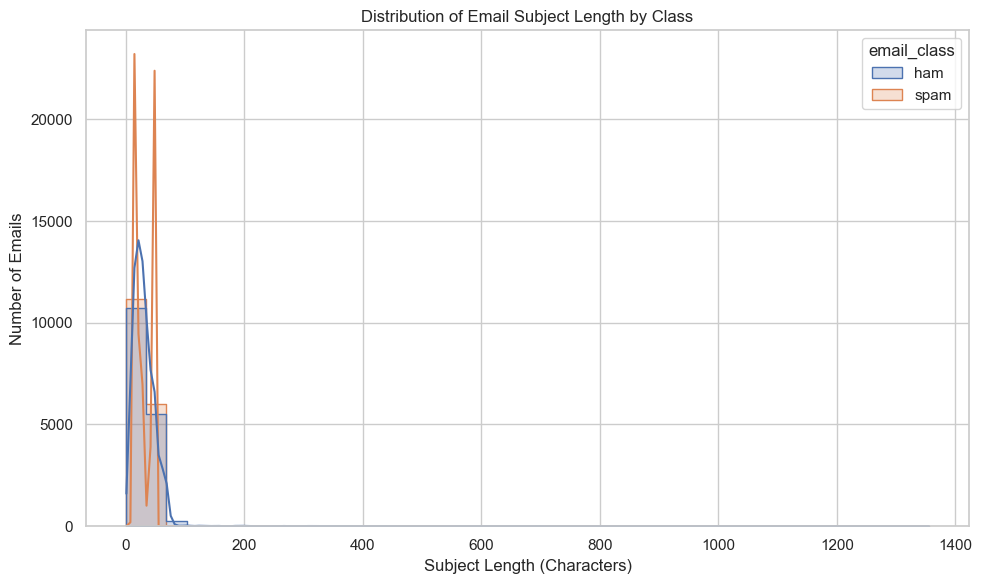

In [46]:
possible_subject_columns = ["Subject", "subject"]
subject_col = None

for column in possible_subject_columns:
    if column in df_email.columns:
        subject_col = column
        break

if subject_col:
    print(f"Subject column identified as: {subject_col}")
    subject_length = df_email[subject_col].fillna("").astype(str).str.len()
    
    print("\nSubject Length Statistics:")
    print(subject_length.describe())
    
    subject_plot_df = pd.DataFrame({
        "subject_length": subject_length,
        "email_class": df_email[target_col]
    })
    
    plt.figure(figsize=(10, 6))
    sns.histplot(data=subject_plot_df, x="subject_length", hue="email_class", bins=40, kde=True, element="step")
    plt.title("Distribution of Email Subject Length by Class")
    plt.xlabel("Subject Length (Characters)")
    plt.ylabel("Number of Emails")
    plt.tight_layout()
    
    plot_path = os.path.join(OUTPUT_DIR, "email_subject_length_distribution.png")
    plt.savefig(plot_path, dpi=300)
    print(f"Saved plot to: {plot_path}")
    plt.show()
else:
    print("No subject column found.")


## Email Dataset Observations

- Number of emails: [PLACEHOLDER]
- Number of columns: [PLACEHOLDER]
- Missing values: [PLACEHOLDER]
- Duplicate records: [PLACEHOLDER]
- Spam samples: [PLACEHOLDER]
- Ham samples: [PLACEHOLDER]
- Class balance: [PLACEHOLDER]
- Average email length: [PLACEHOLDER]
- Median email length: [PLACEHOLDER]


# 5. PhiUSIIL Phishing URL Dataset


## 5.1 Load Dataset


In [47]:
print(f"Loading URL dataset from: {URL_DATA_PATH}")
try:
    df_url = pd.read_csv(URL_DATA_PATH)
    print("Dataset loaded successfully!")
except FileNotFoundError:
    print("ERROR: URL dataset not found. Please check the path.")
except Exception as e:
    print(f"ERROR: {e}")


Loading URL dataset from: c:\Users\admin\Desktop\ML CP\data\raw\PhiUSIIL_Phishing_URL_Dataset.csv
Dataset loaded successfully!


## 5.2 Dataset Shape


In [48]:
rows, columns = df_url.shape
print(f"Number of rows (URLs): {rows}")
print(f"Number of columns (features): {columns}")


Number of rows (URLs): 235795
Number of columns (features): 56


## 5.3 All Column Names


In [49]:
print("URL Dataset Column Names:")
for index, column in enumerate(df_url.columns, start=1):
    print(f"{index}. {column}")


URL Dataset Column Names:
1. FILENAME
2. URL
3. URLLength
4. Domain
5. DomainLength
6. IsDomainIP
7. TLD
8. URLSimilarityIndex
9. CharContinuationRate
10. TLDLegitimateProb
11. URLCharProb
12. TLDLength
13. NoOfSubDomain
14. HasObfuscation
15. NoOfObfuscatedChar
16. ObfuscationRatio
17. NoOfLettersInURL
18. LetterRatioInURL
19. NoOfDegitsInURL
20. DegitRatioInURL
21. NoOfEqualsInURL
22. NoOfQMarkInURL
23. NoOfAmpersandInURL
24. NoOfOtherSpecialCharsInURL
25. SpacialCharRatioInURL
26. IsHTTPS
27. LineOfCode
28. LargestLineLength
29. HasTitle
30. Title
31. DomainTitleMatchScore
32. URLTitleMatchScore
33. HasFavicon
34. Robots
35. IsResponsive
36. NoOfURLRedirect
37. NoOfSelfRedirect
38. HasDescription
39. NoOfPopup
40. NoOfiFrame
41. HasExternalFormSubmit
42. HasSocialNet
43. HasSubmitButton
44. HasHiddenFields
45. HasPasswordField
46. Bank
47. Pay
48. Crypto
49. HasCopyrightInfo
50. NoOfImage
51. NoOfCSS
52. NoOfJS
53. NoOfSelfRef
54. NoOfEmptyRef
55. NoOfExternalRef
56. label


## 5.4 Data Types


In [50]:
print("URL Dataset Data Types Summary:")
print(df_url.dtypes.value_counts())


URL Dataset Data Types Summary:
int64      41
float64    10
object      5
Name: count, dtype: int64


## 5.5 First 5 Records


In [51]:
# Display the first 5 records of the URL dataset
df_url.head()


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


## 5.6 Missing Values


In [52]:
missing_values = df_url.isnull().sum().sort_values(ascending=False)
missing_columns = missing_values[missing_values > 0]

if missing_columns.empty:
    print("No missing values found.")
else:
    print("Missing values per column:")
    print(missing_columns)
    print(f"\nTotal missing values: {missing_values.sum()}")


No missing values found.


## 5.7 Duplicate Records


In [53]:
duplicate_rows = df_url.duplicated().sum()
print(f"Completely duplicate rows: {duplicate_rows}")
print(f"Duplicate percentage: {(duplicate_rows / len(df_url)) * 100:.2f}%")


Completely duplicate rows: 0
Duplicate percentage: 0.00%


## 5.8 Identify Target Column


In [54]:
possible_target_columns = ["label", "Label", "class", "Class", "phishing", "Phishing", "Result"]
target_col_url = None

for column in possible_target_columns:
    if column in df_url.columns:
        target_col_url = column
        break

if target_col_url is None:
    print("WARNING: Could not automatically identify the URL target column.")
else:
    print(f"Target column identified as: '{target_col_url}'")


Target column identified as: 'label'


## 5.9 Identify URL Column


In [55]:
possible_url_columns = ["URL", "url", "Url", "Domain", "domain"]
url_col = None

for column in possible_url_columns:
    if column in df_url.columns:
        url_col = column
        break

print(f"URL column identified as: {url_col}")


URL column identified as: URL


## 5.10 Legitimate vs Phishing Distribution


In [56]:
class_distribution = df_url[target_col_url].value_counts(dropna=False)
print("Class Counts:")
print(class_distribution)

class_percentage = df_url[target_col_url].value_counts(normalize=True, dropna=False) * 100
print("\nClass Percentage:")
print(class_percentage.round(2))


Class Counts:
label
1    134850
0    100945
Name: count, dtype: int64

Class Percentage:
label
1    57.19
0    42.81
Name: proportion, dtype: float64


## 5.11 Class Distribution Visualization


Saved plot to: c:\Users\admin\Desktop\ML CP\outputs\eda\url_class_distribution.png


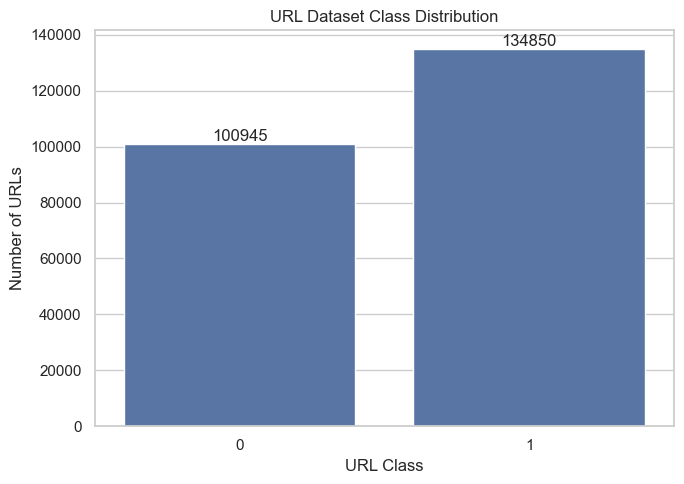

In [57]:
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df_url, x=target_col_url)
plt.title("URL Dataset Class Distribution")
plt.xlabel("URL Class")
plt.ylabel("Number of URLs")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plot_path = os.path.join(OUTPUT_DIR, "url_class_distribution.png")
plt.savefig(plot_path, dpi=300)
print(f"Saved plot to: {plot_path}")
plt.show()


## 5.12 Numerical Feature Summary


In [58]:
numerical_columns = df_url.select_dtypes(include=["number"]).columns.tolist()

if target_col_url in numerical_columns:
    numerical_columns.remove(target_col_url)

print(f"Number of numerical features: {len(numerical_columns)}")

# Show summary statistics for numerical features (transposed for readability)
df_url[numerical_columns].describe().T


Number of numerical features: 50


,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.573095,41.314153,13.000000,23.000000,27.000000,34.000000,6.097000e+03
DomainLength,235795.0,21.470396,9.150793,4.000000,16.000000,20.000000,24.000000,1.100000e+02
IsDomainIP,235795.0,0.002706,0.051946,0.000000,0.000000,0.000000,0.000000,1.000000e+00
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,57.024793,100.000000,100.000000,1.000000e+02
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.680000,1.000000,1.000000,1.000000e+00
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.005977,0.079963,0.522907,5.229071e-01
URLCharProb,235795.0,0.055747,0.010587,0.001083,0.050747,0.057970,0.062875,9.082366e-02
TLDLength,235795.0,2.764456,0.599739,2.000000,2.000000,3.000000,3.000000,1.300000e+01
NoOfSubDomain,235795.0,1.164758,0.600969,0.000000,1.000000,1.000000,1.000000,1.000000e+01
HasObfuscation,235795.0,0.002057,0.045306,0.000000,0.000000,0.000000,0.000000,1.000000e+00


## 5.13 Important URL Feature Distributions


Found 5 predefined important features.


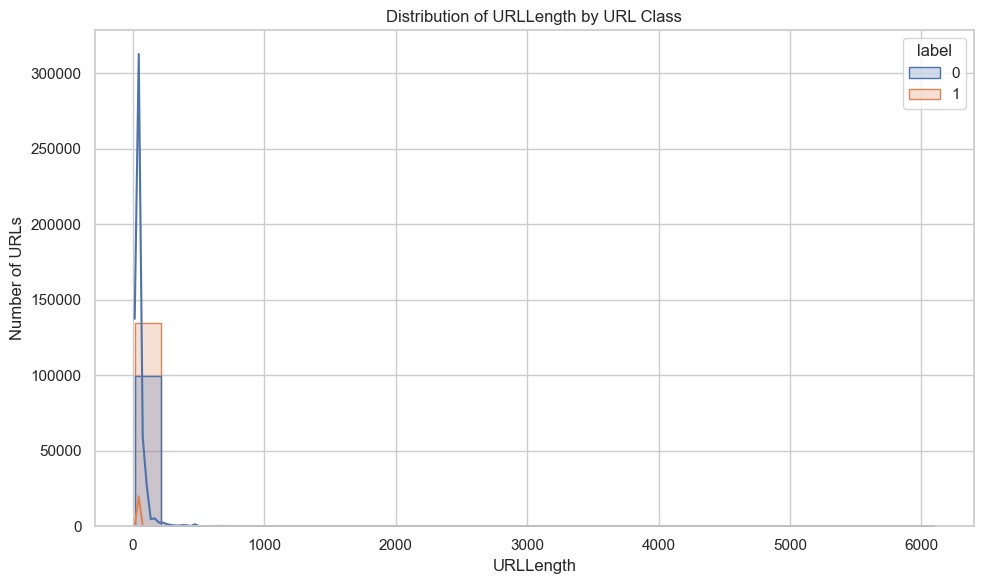

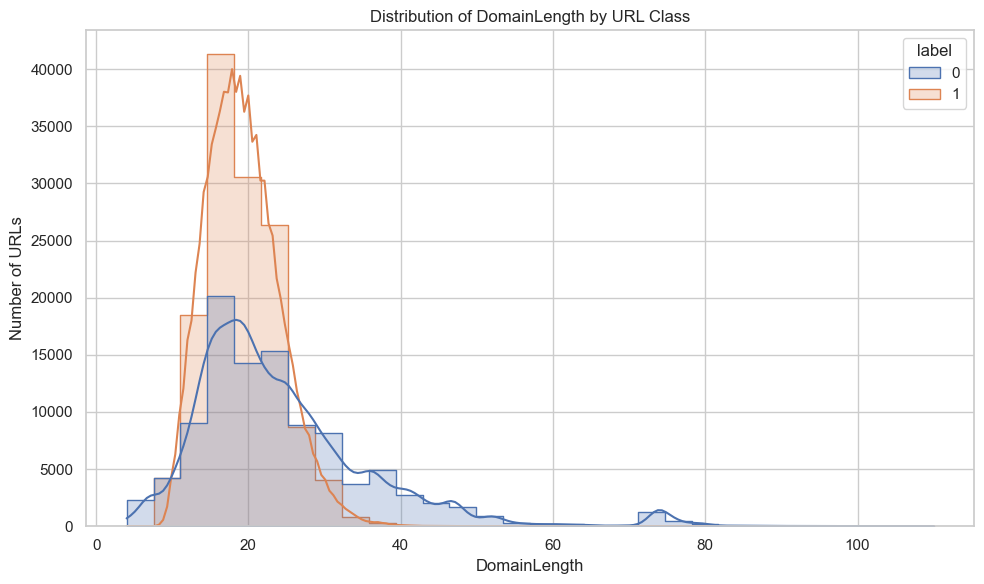

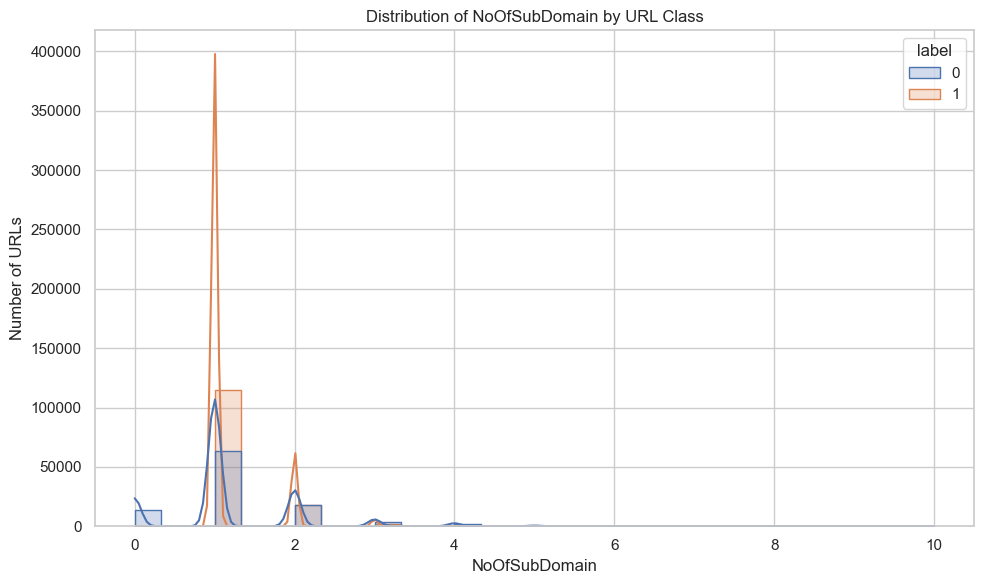

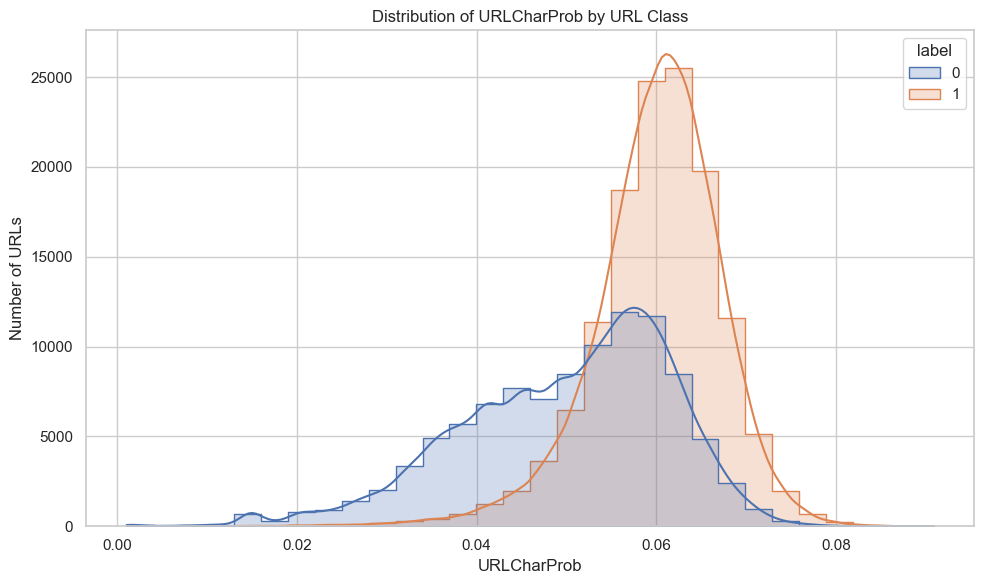

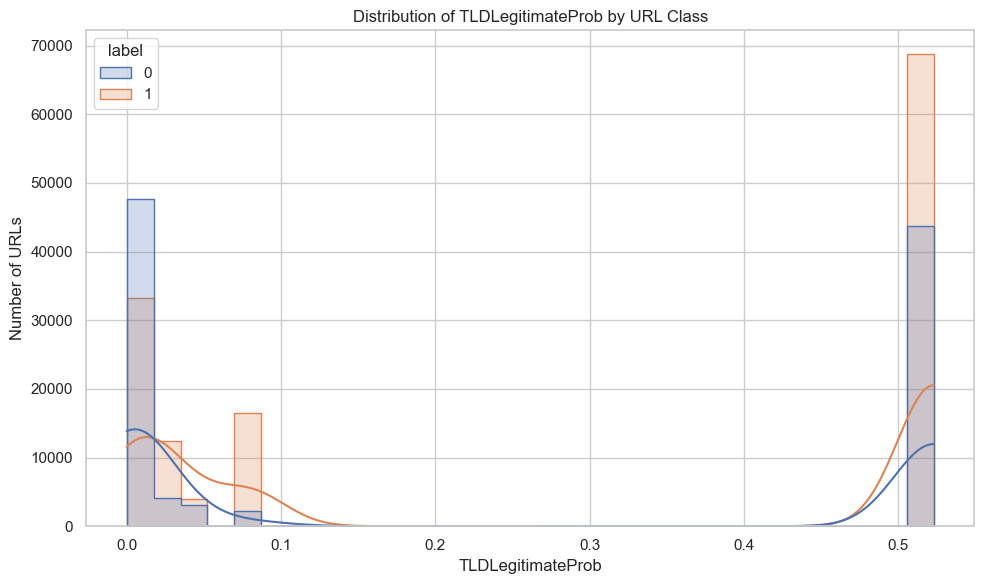

In [59]:
preferred_features = [
    "URLLength", "DomainLength", "NoOfDots", "NoOfHyphen", "NoOfSubDomain",
    "NoOfSpecialChars", "NoOfDigits", "HasHTTPS", "URLCharProb", "TLDLegitimateProb"
]

available_features = [f for f in preferred_features if f in df_url.columns]

print(f"Found {len(available_features)} predefined important features.")

features_to_plot = available_features[:6] # Plot max 6 features

for feature in features_to_plot:
    plt.figure(figsize=(10, 6))
    sns.histplot(data=df_url, x=feature, hue=target_col_url, bins=30, kde=True, element="step")
    plt.title(f"Distribution of {feature} by URL Class")
    plt.xlabel(feature)
    plt.ylabel("Number of URLs")
    plt.tight_layout()
    
    safe_feature_name = feature.replace("/", "_")
    plot_path = os.path.join(OUTPUT_DIR, f"url_feature_{safe_feature_name}.png")
    plt.savefig(plot_path, dpi=300)
    plt.show()


## 5.14 Correlation Analysis


Saved correlation heatmap to: c:\Users\admin\Desktop\ML CP\outputs\eda\url_feature_correlation_heatmap.png


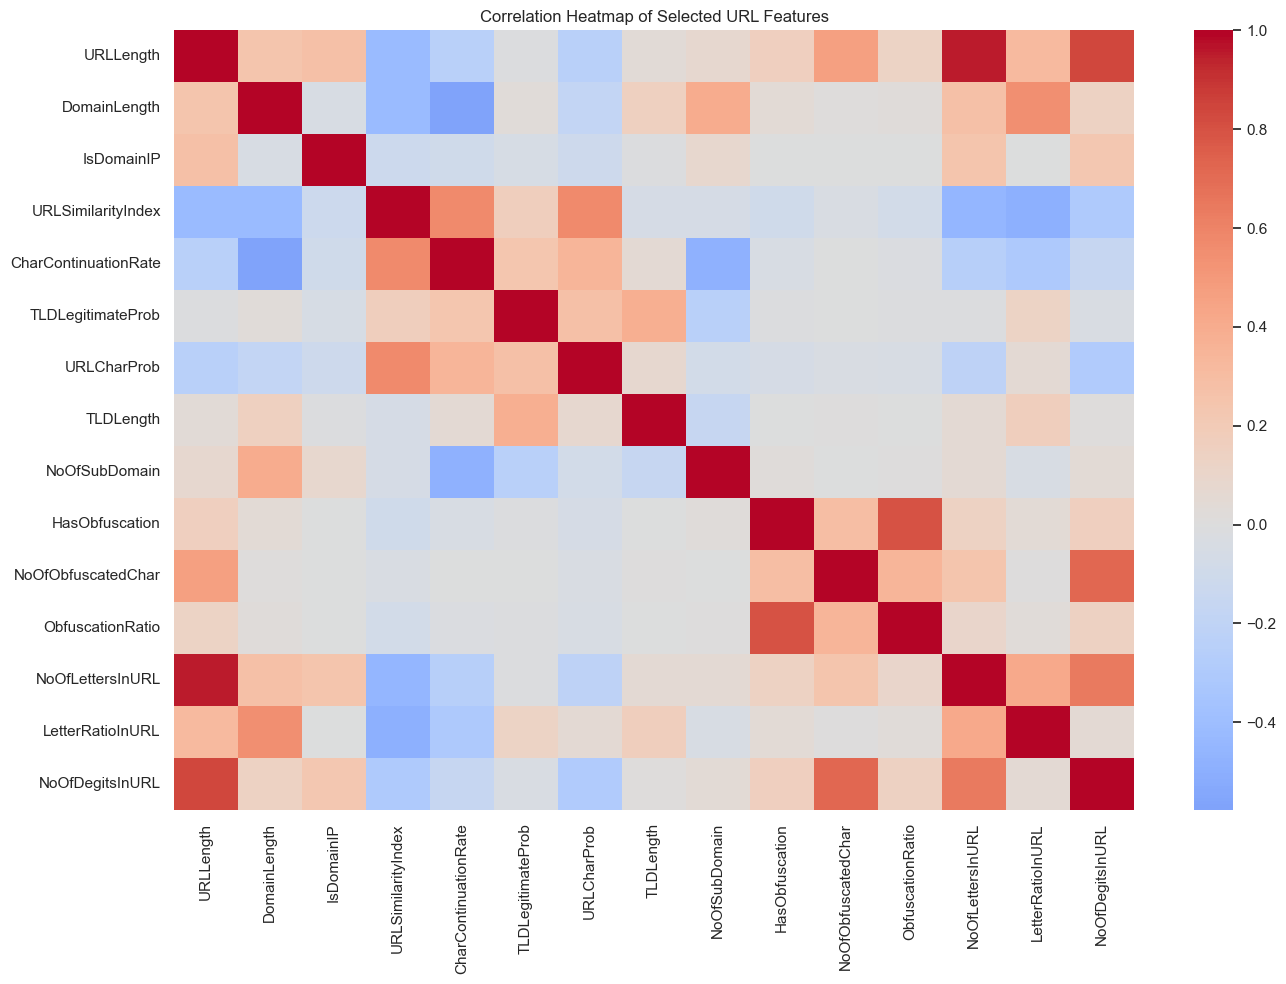

In [60]:
correlation_features = numerical_columns[:15] # Limit to 15 to keep it readable

if len(correlation_features) >= 2:
    correlation_matrix = df_url[correlation_features].corr()
    
    plt.figure(figsize=(14, 10))
    sns.heatmap(correlation_matrix, annot=False, cmap="coolwarm", center=0)
    plt.title("Correlation Heatmap of Selected URL Features")
    plt.tight_layout()
    
    plot_path = os.path.join(OUTPUT_DIR, "url_feature_correlation_heatmap.png")
    plt.savefig(plot_path, dpi=300)
    print(f"Saved correlation heatmap to: {plot_path}")
    plt.show()
else:
    print("Not enough numerical features for correlation analysis.")


## URL Dataset Observations

- Number of URLs: [PLACEHOLDER]
- Number of features: [PLACEHOLDER]
- Missing values: [PLACEHOLDER]
- Duplicate records: [PLACEHOLDER]
- Phishing samples: [PLACEHOLDER]
- Legitimate samples: [PLACEHOLDER]
- Class balance: [PLACEHOLDER]
